  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
八代の10分雨量Excelファイル（.xlsx）を選択してください:


Saving 東京中央集中　75mm.xlsx to 東京中央集中　75mm.xlsx
読み込んだシートの列一覧: ['Rt']
採用した雨量列: Rt


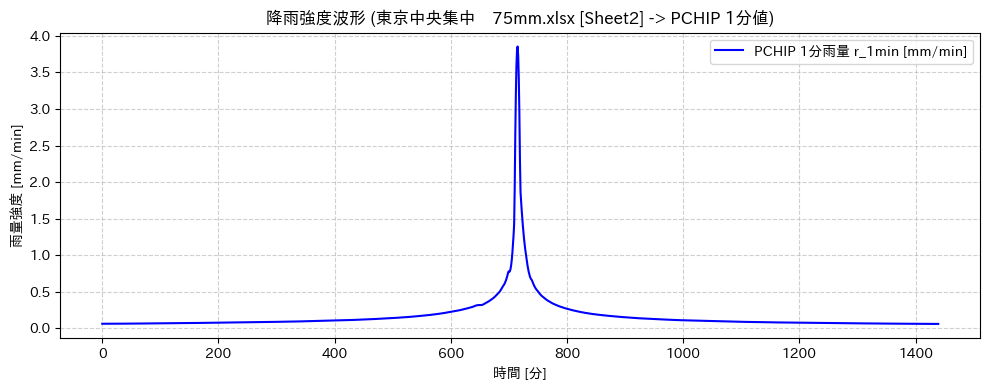

総雨量: 251.79 mm
最大1分雨量: 3.8553 mm/min


In [ ]:
#step1
# 1. 日本語フォント設定
!pip install -q japanize-matplotlib
import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files
from scipy.interpolate import PchipInterpolator

# 2. ファイルアップロード
print("八代の10分雨量Excelファイル（.xlsx）を選択してください:")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

# 3. Sheet2（2番目のシート）を読み込み
df = pd.read_excel(file_name, sheet_name=1)
print(f"読み込んだシートの列一覧: {list(df.columns)}")

# 雨量列の自動判定
rain_col = None
for col in df.columns:
  if any(keyword in str(col).lower() for keyword in ["雨量", "降雨", "rain"]):
    rain_col = col
    break

if rain_col is None:
  max_valid_count = 0
  for col in df.columns:
    s = pd.to_numeric(df[col], errors="coerce")
    valid_count = (s > 0).sum()
    if valid_count > max_valid_count:
      max_valid_count = valid_count
      rain_col = col

print(f"採用した雨量列: {rain_col}")

# 10分雨量配列の作成
r_10min = (
    pd.to_numeric(df[rain_col], errors="coerce").fillna(0.0).values.astype(float)
)

# 4. 累加雨量に対する PCHIP スプライン補間
cum_10min = np.insert(np.cumsum(r_10min), 0, 0.0)
t_10min = np.arange(len(cum_10min)) * 10
t_1min = np.arange(0, t_10min[-1] + 1, 1)

pchip = PchipInterpolator(t_10min, cum_10min)
cum_1min = pchip(t_1min)

# 1分雨量強度 [mm/min] の算出
r_1min = np.diff(cum_1min)
r_1min = np.clip(r_1min, 0.0, None)

# 5. 確認プロット
plt.figure(figsize=(10, 4))
plt.plot(r_1min, label="PCHIP 1分雨量 r_1min [mm/min]", color="blue")
plt.xlabel("時間 [分]")
plt.ylabel("雨量強度 [mm/min]")
plt.title(f"降雨強度波形 ({file_name} [Sheet2] -> PCHIP 1分値)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(f"総雨量: {np.sum(r_1min):.2f} mm")
print(f"最大1分雨量: {np.max(r_1min):.4f} mm/min")

校庭面積：4000 m²
最大貯留水深：20 cm
最大貯留容量：800 m³
総降雨量：251.79 mm


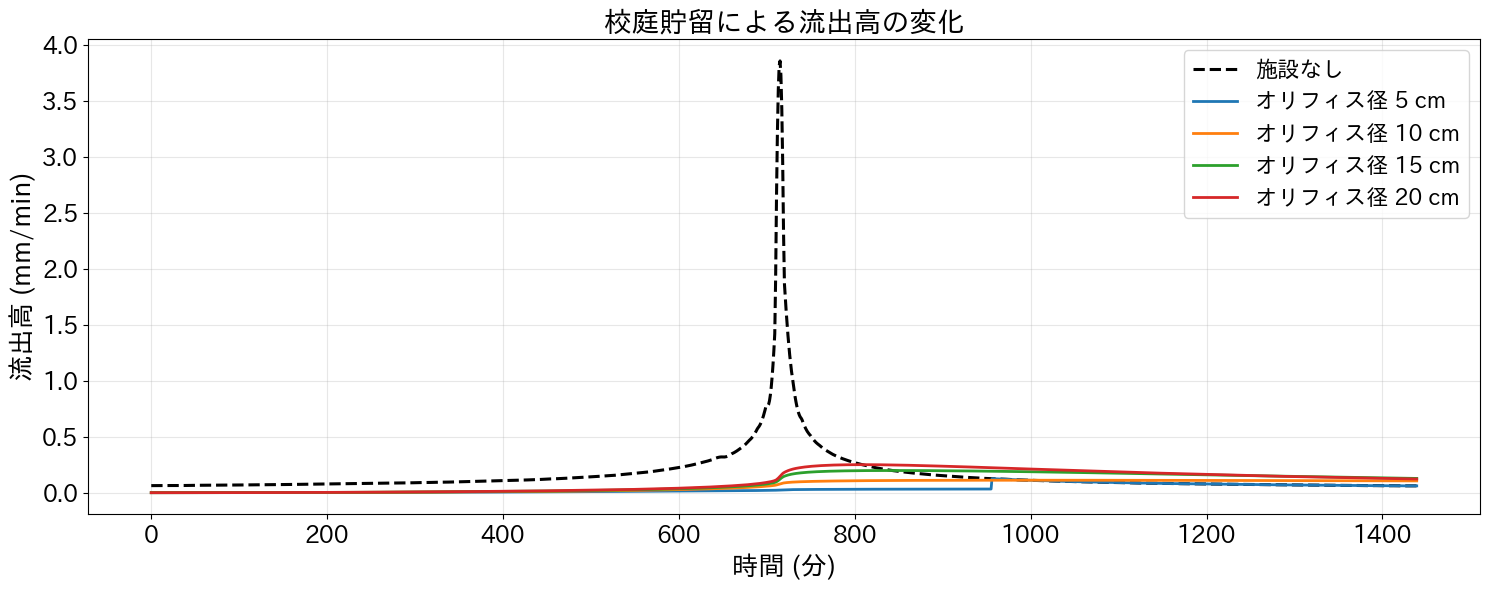

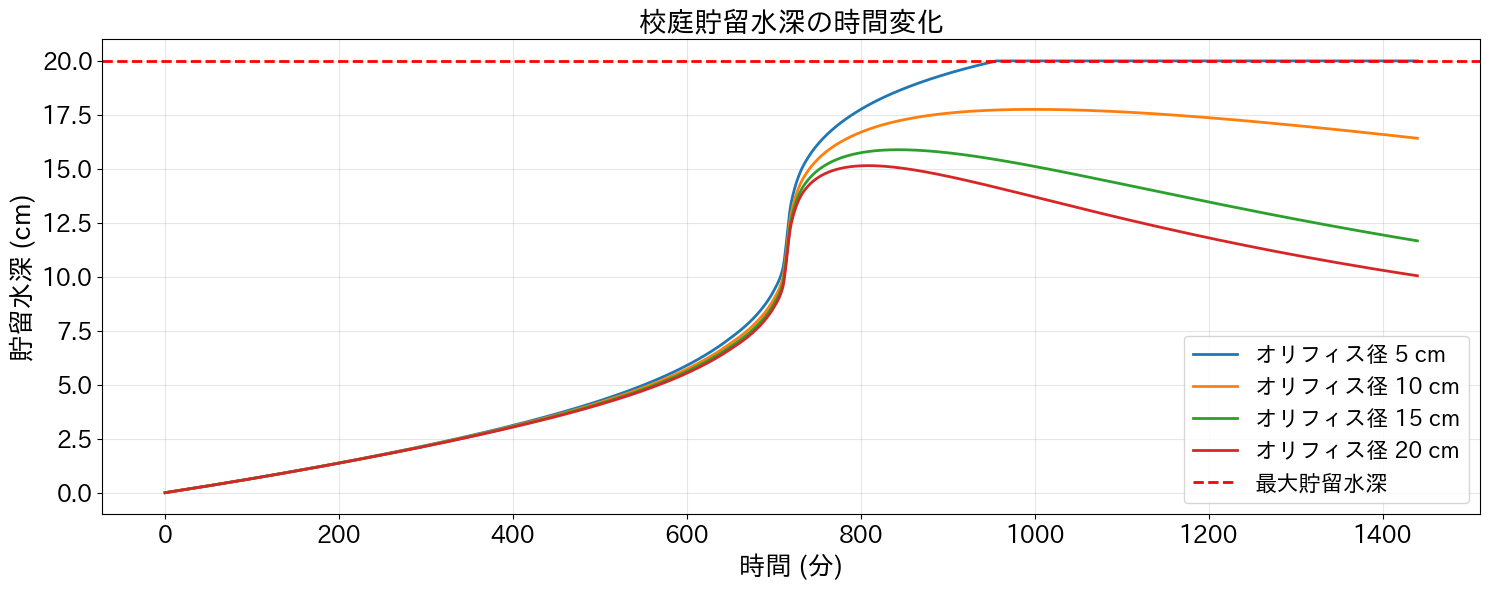


===== オリフィス径別比較 =====
 孔径(cm)  最大水深(cm)  最大流出高(mm/min)  ピーク低減率(%)  越流量(m³)  越流時間(分)  最終貯留量(m³)
      5    20.000          0.125     96.754   95.582      484    800.000
     10    17.755          0.111     97.113    0.000        0    656.703
     15    15.886          0.198     94.863    0.000        0    466.619
     20    15.149          0.250     93.507    0.000        0    401.920

===== 今回の降雨に対する最小ピーク径 =====
オリフィス径：10 cm
最大流出高：0.1113 mm/min
ピーク低減率：97.1 %
越流量：0.0 m³


In [ ]:

# ============================================================
# Step 2：校庭貯留モデル
# 面積4000m²、最大貯留水深20cm
# オリフィス径 5,10,15,20cm の比較
# Step 1 の r_1min をそのまま使用
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. 基本条件
# ------------------------------------------------------------

AREA = 4000.0         # 校庭面積 [m²]
H_MAX = 0.20          # 最大貯留水深 [m]
CD = 0.60             # 流量係数
G = 9.81              # 重力加速度 [m/s²]

DIAMETERS_CM = [5, 10, 15, 20]

DT = 5.0              # 内部計算刻み [秒]
MAX_STORAGE = AREA * H_MAX

rain = np.asarray(r_1min, dtype=float)

if not np.all(np.isfinite(rain)) or np.any(rain < 0):
    raise ValueError("r_1min に不正な値があります")

print(f"校庭面積：{AREA:.0f} m²")
print(f"最大貯留水深：{H_MAX*100:.0f} cm")
print(f"最大貯留容量：{MAX_STORAGE:.0f} m³")
print(f"総降雨量：{rain.sum():.2f} mm")


# ------------------------------------------------------------
# 2. 円形オリフィスの流量計算
# 孔の下端を校庭地盤面とする
# 部分水没状態も考慮
# ------------------------------------------------------------

def orifice_flow(h, diameter_cm):

    D = diameter_cm / 100.0
    R = D / 2.0

    if h <= 0:
        return 0.0

    # 開口部を水平帯に分割
    n = 100
    dz = D / n
    z = (np.arange(n) + 0.5) * dz

    width = 2 * np.sqrt(
        np.maximum(R**2 - (z-R)**2, 0.0)
    )

    head = np.maximum(h-z, 0.0)

    Q = CD * np.sum(
        width * dz * np.sqrt(2*G*head)
    )

    return Q  # [m³/s]


# ------------------------------------------------------------
# 3. 校庭貯留計算
# ------------------------------------------------------------

def school_storage(rain, diameter_cm):

    n = len(rain)

    depth = np.zeros(n+1)
    outflow = np.zeros(n)
    overflow = np.zeros(n)

    storage = 0.0
    substeps = int(round(60.0 / DT))

    for i in range(n):

        vout_total = 0.0
        vover_total = 0.0

        # 1分雨量を内部では一定強度として扱う
        rain_volume_step = (
            rain[i] / 1000.0 * AREA / substeps
        )

        for j in range(substeps):

            storage += rain_volume_step

            # 現在の貯留水深
            h = storage / AREA

            # オリフィス排水
            Q = orifice_flow(h, diameter_cm)
            vout = min(Q * DT, storage)
            storage -= vout

            # 最大貯留容量超過分は越流
            vover = max(storage - MAX_STORAGE, 0.0)
            storage -= vover

            vout_total += vout
            vover_total += vover

        depth[i+1] = storage / AREA

        # 1分平均流量 [m³/s]
        outflow[i] = vout_total / 60.0
        overflow[i] = vover_total / 60.0

    return depth, outflow, overflow


# ------------------------------------------------------------
# 4. 各オリフィス径の計算
# ------------------------------------------------------------

time = np.arange(len(rain))
results = []
hydrographs = {}
depths = {}

for D in DIAMETERS_CM:

    depth, qout, qover = school_storage(rain, D)

    # 流出高 [mm/min]
    runoff = (qout + qover) * 60 / AREA * 1000

    hydrographs[D] = runoff
    depths[D] = depth

    peak = np.max(runoff)
    reduction = (
        (1 - peak / np.max(rain)) * 100
        if np.max(rain) > 0 else 0.0
    )

    results.append({
        "孔径(cm)": D,
        "最大水深(cm)": np.max(depth)*100,
        "最大流出高(mm/min)": peak,
        "ピーク低減率(%)": reduction,
        "越流量(m³)": np.sum(qover)*60,
        "越流時間(分)": np.sum(qover > 1e-12),
        "最終貯留量(m³)": depth[-1]*AREA
    })


# ------------------------------------------------------------
# 5. 流出高波形
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

plt.plot(
    time, rain,
    color="black", linestyle="--",
    linewidth=2.2,
    label="施設なし"
)

for D in DIAMETERS_CM:
    plt.plot(
        time, hydrographs[D],
        linewidth=2,
        label=f"オリフィス径 {D} cm"
    )

plt.xlabel("時間 (分)", fontsize=19)
plt.ylabel("流出高 (mm/min)", fontsize=19)
plt.title("校庭貯留による流出高の変化", fontsize=20)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=16)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. 貯留水深
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

for D in DIAMETERS_CM:
    plt.plot(
        np.arange(len(depths[D])),
        depths[D]*100,
        linewidth=2,
        label=f"オリフィス径 {D} cm"
    )

plt.axhline(
    H_MAX*100,
    color="red",
    linestyle="--",
    linewidth=2,
    label="最大貯留水深"
)

plt.xlabel("時間 (分)", fontsize=19)
plt.ylabel("貯留水深 (cm)", fontsize=19)
plt.title("校庭貯留水深の時間変化", fontsize=20)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=16)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. 比較表
# ------------------------------------------------------------

result_df = pd.DataFrame(results)

print("\n===== オリフィス径別比較 =====")
print(result_df.round(3).to_string(index=False))

best = result_df.loc[
    result_df["最大流出高(mm/min)"].idxmin()
]

print("\n===== 今回の降雨に対する最小ピーク径 =====")
print(f"オリフィス径：{best['孔径(cm)']:.0f} cm")
print(
    f"最大流出高："
    f"{best['最大流出高(mm/min)']:.4f} mm/min"
)
print(
    f"ピーク低減率："
    f"{best['ピーク低減率(%)']:.1f} %"
)
print(
    f"越流量：{best['越流量(m³)']:.1f} m³"
)


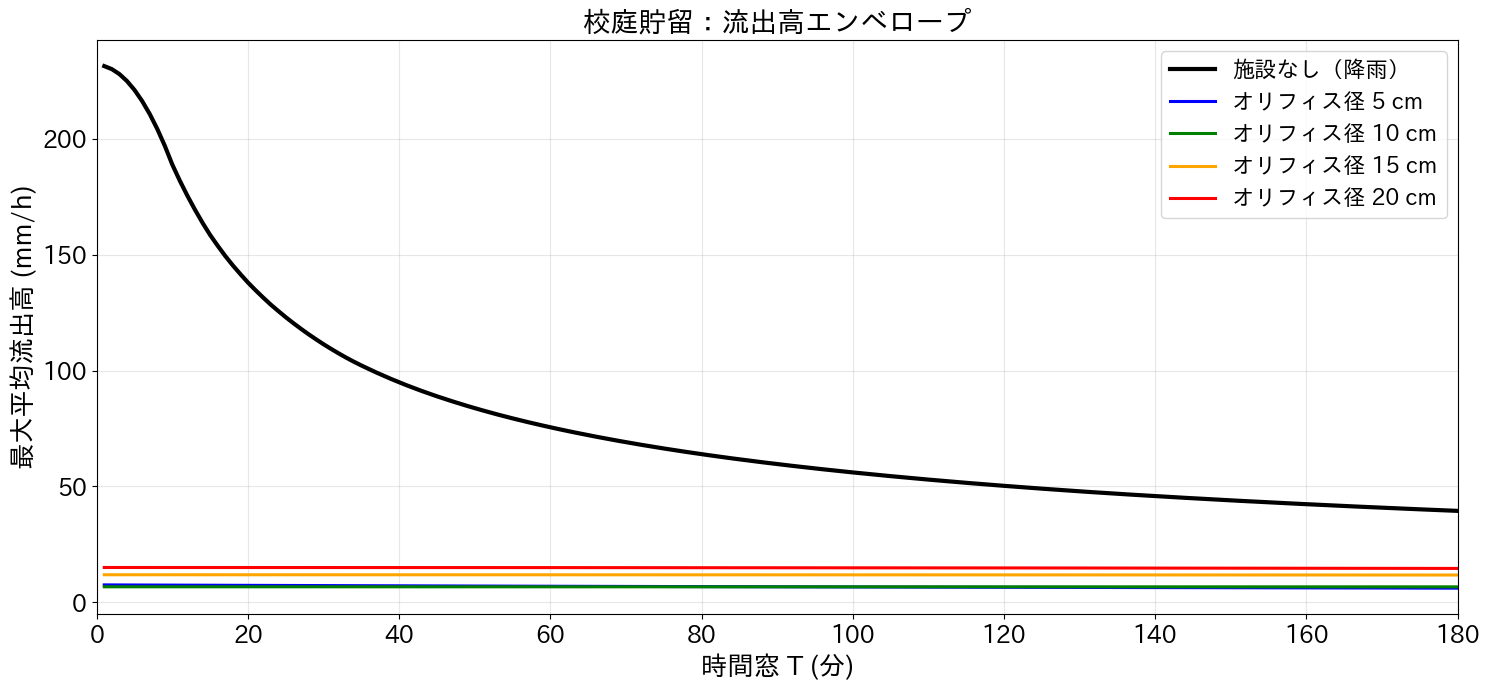

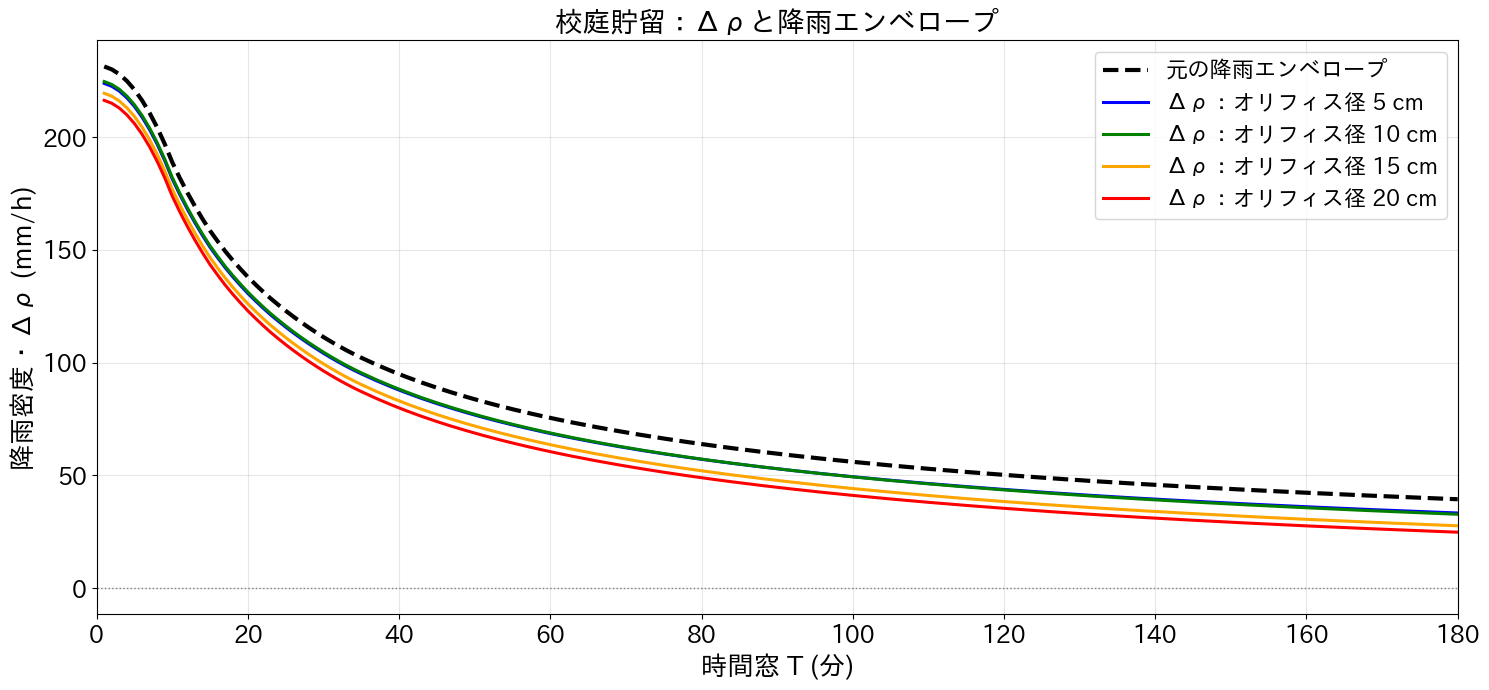

,時間窓(分),施設なし(mm/h),径5cm_流出高(mm/h),径5cm_Δρ(mm/h),径10cm_流出高(mm/h),径10cm_Δρ(mm/h),径15cm_流出高(mm/h),径15cm_Δρ(mm/h),径20cm_流出高(mm/h),径20cm_Δρ(mm/h)
0,1,231.320538,7.509260,223.811277,6.678581,224.641957,11.884077,219.436461,15.020124,216.300414
1,2,230.025280,7.502484,222.522796,6.678581,223.346699,11.884076,218.141204,15.020083,215.005197
2,3,227.886765,7.495734,220.391031,6.678580,221.208185,11.884044,216.002720,15.020022,212.866743
3,4,224.874620,7.485107,217.389513,6.678579,218.196042,11.884028,212.990592,15.019932,209.854688
4,5,221.019218,7.472853,213.546365,6.678577,214.340641,11.883982,209.135236,15.019816,205.999401
5,6,216.290187,7.460118,208.830068,6.678575,209.611612,11.883948,204.406238,15.019676,201.270510
6,7,210.717898,7.447341,203.270556,6.678572,204.039326,11.883888,198.834010,15.019505,195.698392
7,8,204.271980,7.434740,196.837240,6.678570,197.593410,11.883837,192.388143,15.019315,189.252665
8,9,196.982805,7.422435,189.560370,6.678566,190.304238,11.883762,185.099042,15.019087,181.963718
9,10,188.820000,7.410498,181.409502,6.678563,182.141437,11.883695,176.936305,15.018847,173.801153


In [ ]:
# ============================================================
# Step 3：校庭貯留のエンベロープ解析
# ① 流出高エンベロープ
# ② Δρエンベロープ＋元の降雨エンベロープ
# 縦軸：mm/h、横軸：時間窓（分）
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 時間窓
MAX_WINDOW = min(180, len(rain))
windows = np.arange(1, MAX_WINDOW + 1)

# 2. エンベロープ計算関数
def calc_envelope(wave, windows):
    wave = np.asarray(wave, dtype=float)
    cumulative = np.insert(np.cumsum(wave), 0, 0.0)

    envelope = np.zeros(len(windows))

    for i, T in enumerate(windows):
        moving_average = (
            cumulative[T:] - cumulative[:-T]
        ) / T
        envelope[i] = np.max(moving_average)

    return envelope

# 3. エンベロープを mm/h に換算
E_natural = calc_envelope(rain, windows) * 60

E_storage = {}
delta_rho = {}

for D in DIAMETERS_CM:
    E_storage[D] = calc_envelope(
        hydrographs[D], windows
    ) * 60

    delta_rho[D] = E_natural - E_storage[D]

colors = {
    5: "blue",
    10: "green",
    15: "orange",
    20: "red"
}

# ------------------------------------------------------------
# 4. グラフ①：流出高エンベロープ
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    windows, E_natural,
    color="black",
    linewidth=3,
    label="施設なし（降雨）"
)

for D in DIAMETERS_CM:
    plt.plot(
        windows, E_storage[D],
        color=colors.get(D, None),
        linewidth=2.2,
        label=f"オリフィス径 {D} cm"
    )

plt.xlabel("時間窓 T (分)", fontsize=19)
plt.ylabel("最大平均流出高 (mm/h)", fontsize=19)
plt.title("校庭貯留：流出高エンベロープ", fontsize=20)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, MAX_WINDOW)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. グラフ②：Δρ＋元の降雨エンベロープ
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

# 元の降雨エンベロープ
plt.plot(
    windows, E_natural,
    color="black",
    linestyle="--",
    linewidth=3,
    label="元の降雨エンベロープ"
)

# Δρ
for D in DIAMETERS_CM:
    plt.plot(
        windows, delta_rho[D],
        color=colors.get(D, None),
        linewidth=2.2,
        label=f"Δρ：オリフィス径 {D} cm"
    )

plt.axhline(
    0, color="gray",
    linestyle=":", linewidth=1
)

plt.xlabel("時間窓 T (分)", fontsize=19)
plt.ylabel("降雨密度・Δρ (mm/h)", fontsize=19)
plt.title("校庭貯留：Δρと降雨エンベロープ", fontsize=20)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, MAX_WINDOW)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. 結果表
# ------------------------------------------------------------

envelope_df = pd.DataFrame({
    "時間窓(分)": windows,
    "施設なし(mm/h)": E_natural
})

for D in DIAMETERS_CM:
    envelope_df[f"径{D}cm_流出高(mm/h)"] = E_storage[D]
    envelope_df[f"径{D}cm_Δρ(mm/h)"] = delta_rho[D]

display(envelope_df.head(10))

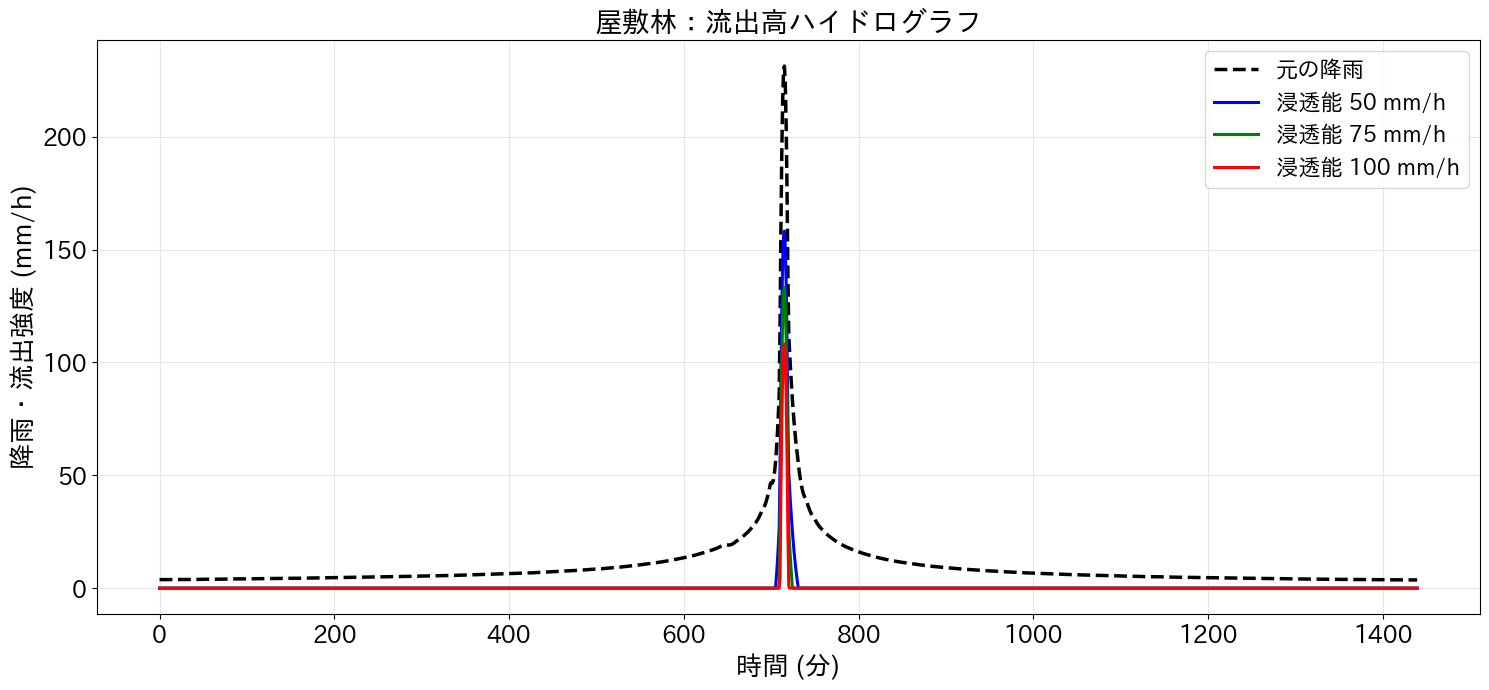

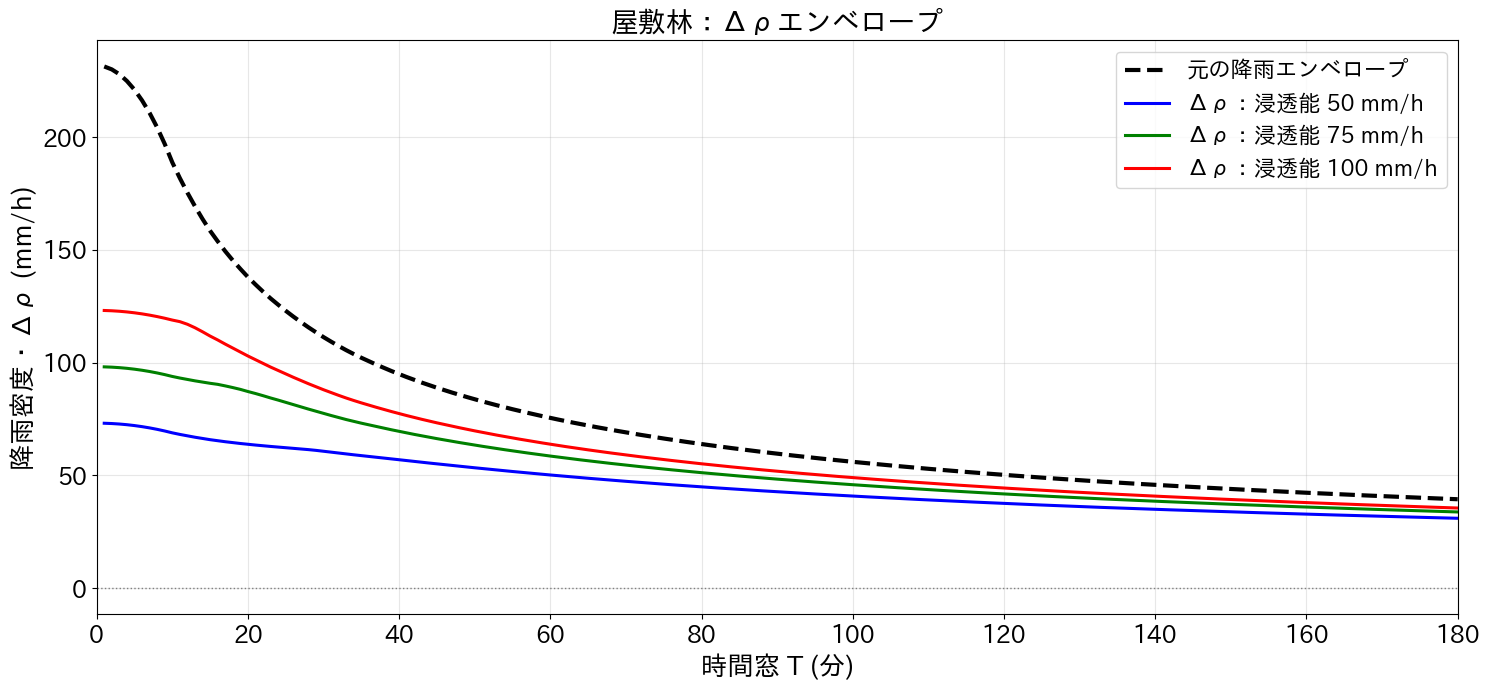

===== 屋敷林の流出計算結果 =====


,浸透能(mm/h),総降雨量(mm),遮断蒸発量(mm),総浸透量(mm),総流出高(mm),最大流出強度(mm/h),総流出量(m³)
0,50,251.79,25.179,201.302,25.309,158.188,30.371
1,75,251.79,25.179,209.691,16.920,133.188,20.304
2,100,251.79,25.179,214.943,11.668,108.188,14.002


===== 屋敷林のエンベロープ結果 =====


,時間窓(分),元の降雨エンベロープ(mm/h),浸透能50_流出エンベロープ(mm/h),浸透能50_Δρ(mm/h),浸透能75_流出エンベロープ(mm/h),浸透能75_Δρ(mm/h),浸透能100_流出エンベロープ(mm/h),浸透能100_Δρ(mm/h)
0,1,231.320538,158.188484,73.132054,133.188484,98.132054,108.188484,123.132054
1,2,230.025280,157.022752,73.002528,132.022752,98.002528,107.022752,123.002528
2,3,227.886765,155.098088,72.788676,130.098088,97.788676,105.098088,122.788676
3,4,224.874620,152.387158,72.487462,127.387158,97.487462,102.387158,122.487462
4,5,221.019218,148.917296,72.101922,123.917296,97.101922,98.917296,122.101922
5,6,216.290187,144.661168,71.629019,119.661168,96.629019,94.661168,121.629019
6,7,210.717898,139.646108,71.071790,114.646108,96.071790,89.646108,121.071790
7,8,204.271980,133.844782,70.427198,108.844782,95.427198,83.844782,120.427198
8,9,196.982805,127.284524,69.698280,102.284524,94.698280,77.284524,119.698280
9,10,188.820000,119.938000,68.882000,94.938000,93.882000,69.938000,118.882000


In [ ]:
# ============================================================
# Step 4：屋敷林の浸透・遮断蒸発モデル
# ① 流出高ハイドログラフ
# ② Δρエンベロープ＋元の降雨エンベロープ
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. 基本条件
# ------------------------------------------------------------

FOREST_AREA = 1200.0       # 屋敷林面積 [m²]
INTERCEPTION = 0.10        # 遮断蒸発率 10%
INFILTRATION_RATES = [50, 75, 100]  # 浸透能 [mm/h]

rain = np.asarray(r_1min, dtype=float)  # [mm/min]

if not np.all(np.isfinite(rain)) or np.any(rain < 0):
    raise ValueError("r_1min に不正な値があります")

time = np.arange(len(rain))

# ------------------------------------------------------------
# 2. 屋敷林の流出計算
# 遮断蒸発10% → 残りの雨量から浸透を差し引く
# ------------------------------------------------------------

def forest_runoff(rain_mm_min, infiltration_mm_h):

    # 遮断蒸発後の降雨
    effective_rain = rain_mm_min * (1 - INTERCEPTION)

    # 浸透能をmm/minに換算
    infiltration_mm_min = infiltration_mm_h / 60.0

    # 浸透量
    infiltration = np.minimum(
        effective_rain, infiltration_mm_min
    )

    # 表面流出高 [mm/min]
    runoff = np.maximum(
        effective_rain - infiltration, 0.0
    )

    return runoff, infiltration


# ------------------------------------------------------------
# 3. 各浸透能の流出計算
# ------------------------------------------------------------

forest_hydrographs = {}
forest_results = []

for f in INFILTRATION_RATES:

    runoff, infiltration = forest_runoff(rain, f)
    forest_hydrographs[f] = runoff

    forest_results.append({
        "浸透能(mm/h)": f,
        "総降雨量(mm)": np.sum(rain),
        "遮断蒸発量(mm)": np.sum(rain) * INTERCEPTION,
        "総浸透量(mm)": np.sum(infiltration),
        "総流出高(mm)": np.sum(runoff),
        "最大流出強度(mm/h)": np.max(runoff) * 60,
        "総流出量(m³)": np.sum(runoff) / 1000 * FOREST_AREA
    })


# ------------------------------------------------------------
# 4. グラフ①：流出高ハイドログラフ
# ------------------------------------------------------------

colors = {
    50: "blue",
    75: "green",
    100: "red"
}

plt.figure(figsize=(15, 7))

# 元の降雨波形
plt.plot(
    time, rain * 60,
    color="black",
    linestyle="--",
    linewidth=2.5,
    label="元の降雨"
)

# 浸透能別の流出波形
for f in INFILTRATION_RATES:

    plt.plot(
        time,
        forest_hydrographs[f] * 60,
        color=colors[f],
        linewidth=2.2,
        label=f"浸透能 {f} mm/h"
    )

plt.xlabel("時間 (分)", fontsize=19)
plt.ylabel("降雨・流出強度 (mm/h)", fontsize=19)
plt.title("屋敷林：流出高ハイドログラフ", fontsize=20)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. エンベロープ計算関数
# 各時間窓の移動平均最大値
# ------------------------------------------------------------

def calc_forest_envelope(wave, windows):

    wave = np.asarray(wave, dtype=float)
    cumulative = np.insert(np.cumsum(wave), 0, 0.0)

    envelope = np.zeros(len(windows))

    for i, T in enumerate(windows):

        moving_average = (
            cumulative[T:] - cumulative[:-T]
        ) / T

        envelope[i] = np.max(moving_average)

    return envelope


# ------------------------------------------------------------
# 6. エンベロープとΔρの計算
# ------------------------------------------------------------

MAX_WINDOW = min(180, len(rain))
windows = np.arange(1, MAX_WINDOW + 1)

# 元の降雨エンベロープ [mm/h]
E_rain = calc_forest_envelope(rain, windows) * 60

E_forest = {}
delta_rho_forest = {}

for f in INFILTRATION_RATES:

    E_forest[f] = calc_forest_envelope(
        forest_hydrographs[f], windows
    ) * 60

    # エンベロープ最大値同士の差
    delta_rho_forest[f] = E_rain - E_forest[f]


# ------------------------------------------------------------
# 7. グラフ②：Δρ＋元の降雨エンベロープ
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    windows, E_rain,
    color="black",
    linestyle="--",
    linewidth=3,
    label="元の降雨エンベロープ"
)

for f in INFILTRATION_RATES:

    plt.plot(
        windows,
        delta_rho_forest[f],
        color=colors[f],
        linewidth=2.2,
        label=f"Δρ：浸透能 {f} mm/h"
    )

plt.axhline(
    0,
    color="gray",
    linestyle=":",
    linewidth=1
)

plt.xlabel("時間窓 T (分)", fontsize=19)
plt.ylabel("降雨密度・Δρ (mm/h)", fontsize=19)
plt.title("屋敷林：Δρエンベロープ", fontsize=20)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, MAX_WINDOW)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. 結果表
# ------------------------------------------------------------

forest_df = pd.DataFrame(forest_results)

print("===== 屋敷林の流出計算結果 =====")
display(forest_df.round(3))

envelope_forest_df = pd.DataFrame({
    "時間窓(分)": windows,
    "元の降雨エンベロープ(mm/h)": E_rain
})

for f in INFILTRATION_RATES:
    envelope_forest_df[
        f"浸透能{f}_流出エンベロープ(mm/h)"
    ] = E_forest[f]

    envelope_forest_df[
        f"浸透能{f}_Δρ(mm/h)"
    ] = delta_rho_forest[f]

print("===== 屋敷林のエンベロープ結果 =====")
display(envelope_forest_df.head(10))

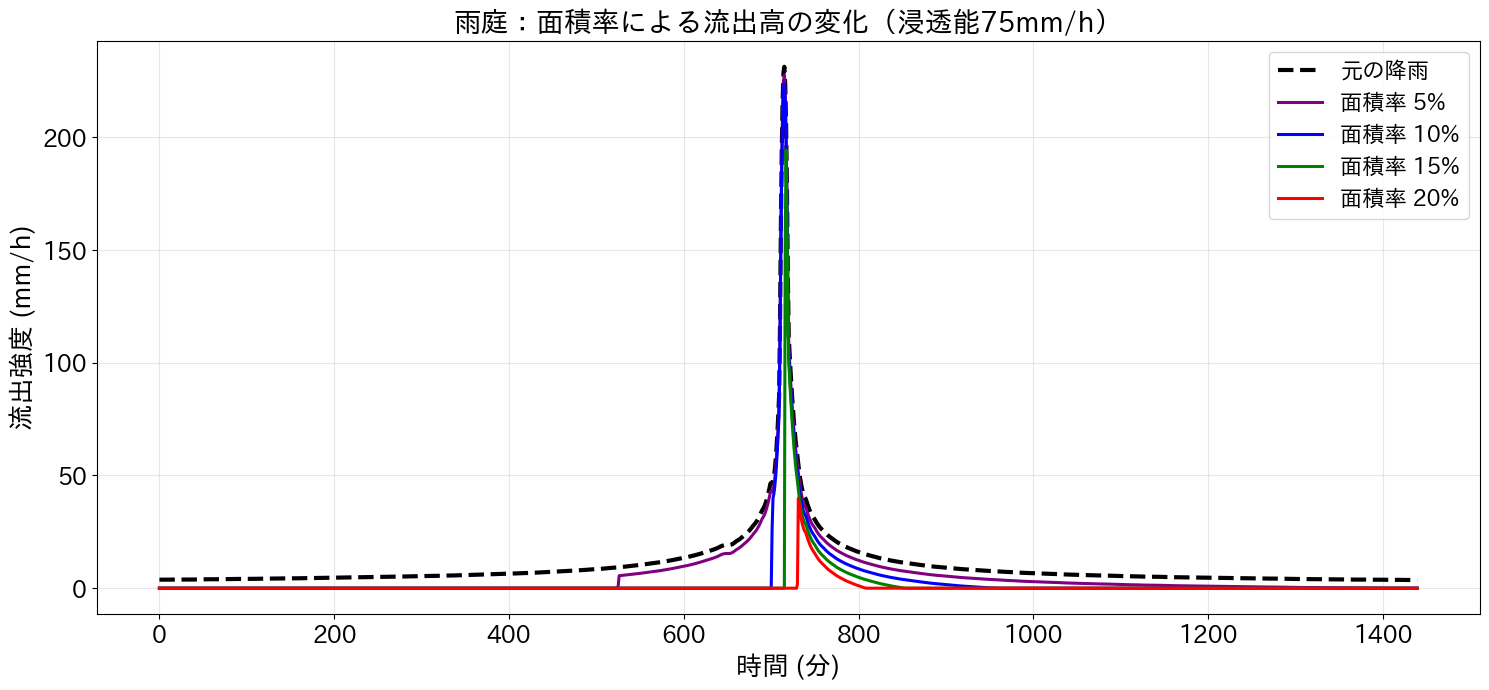

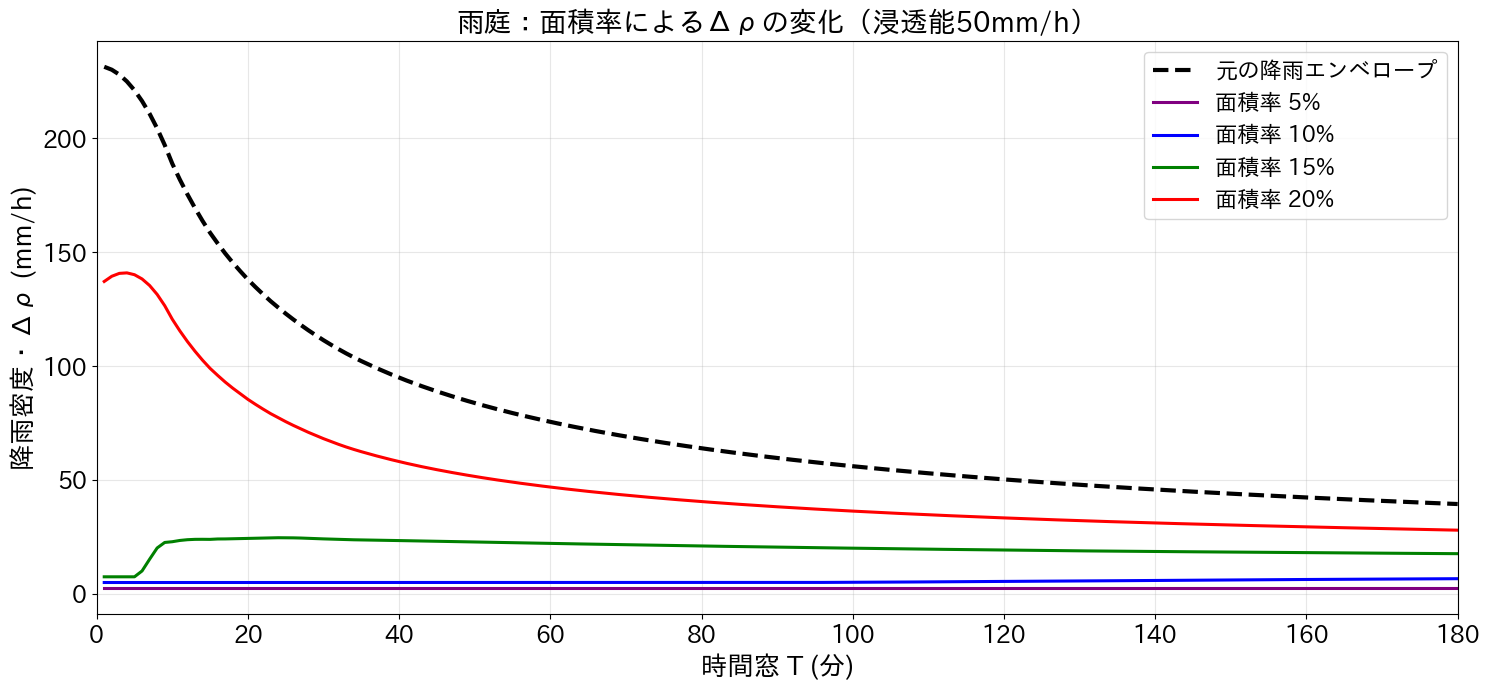

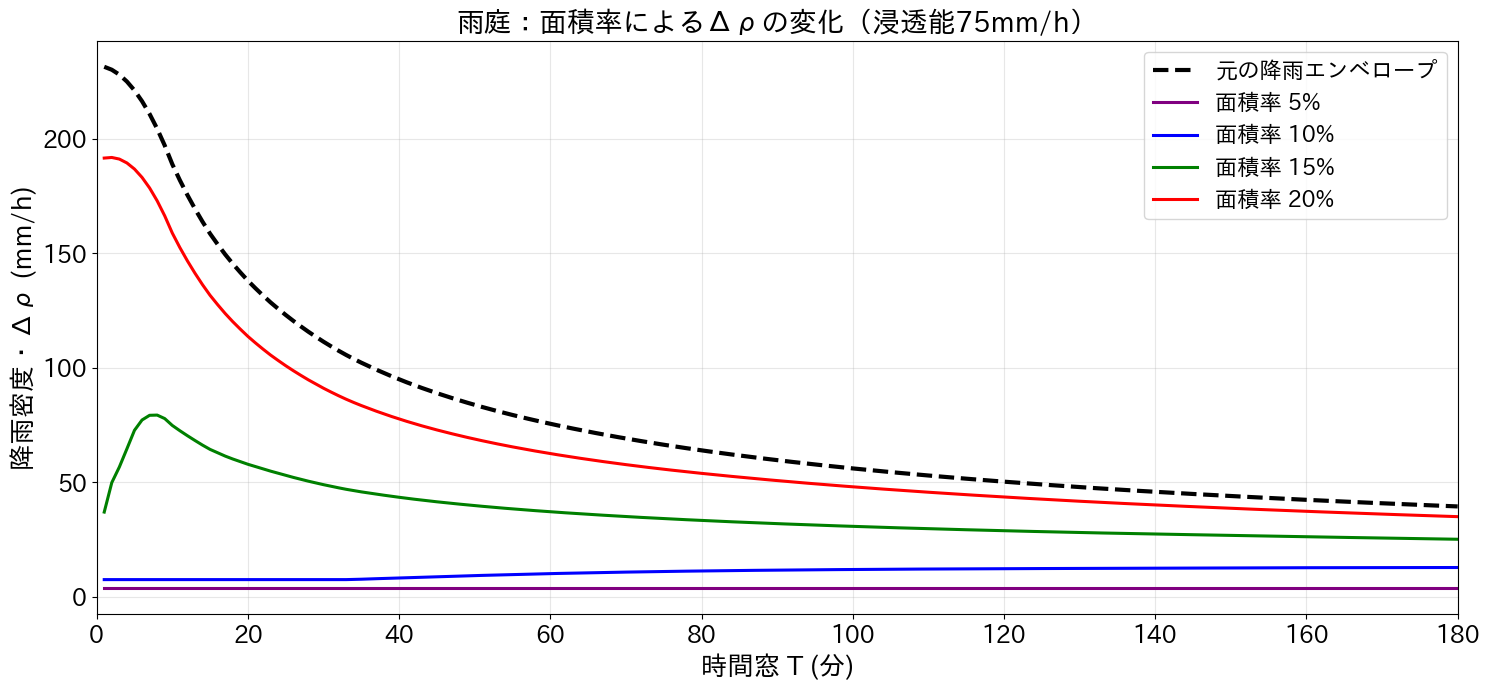

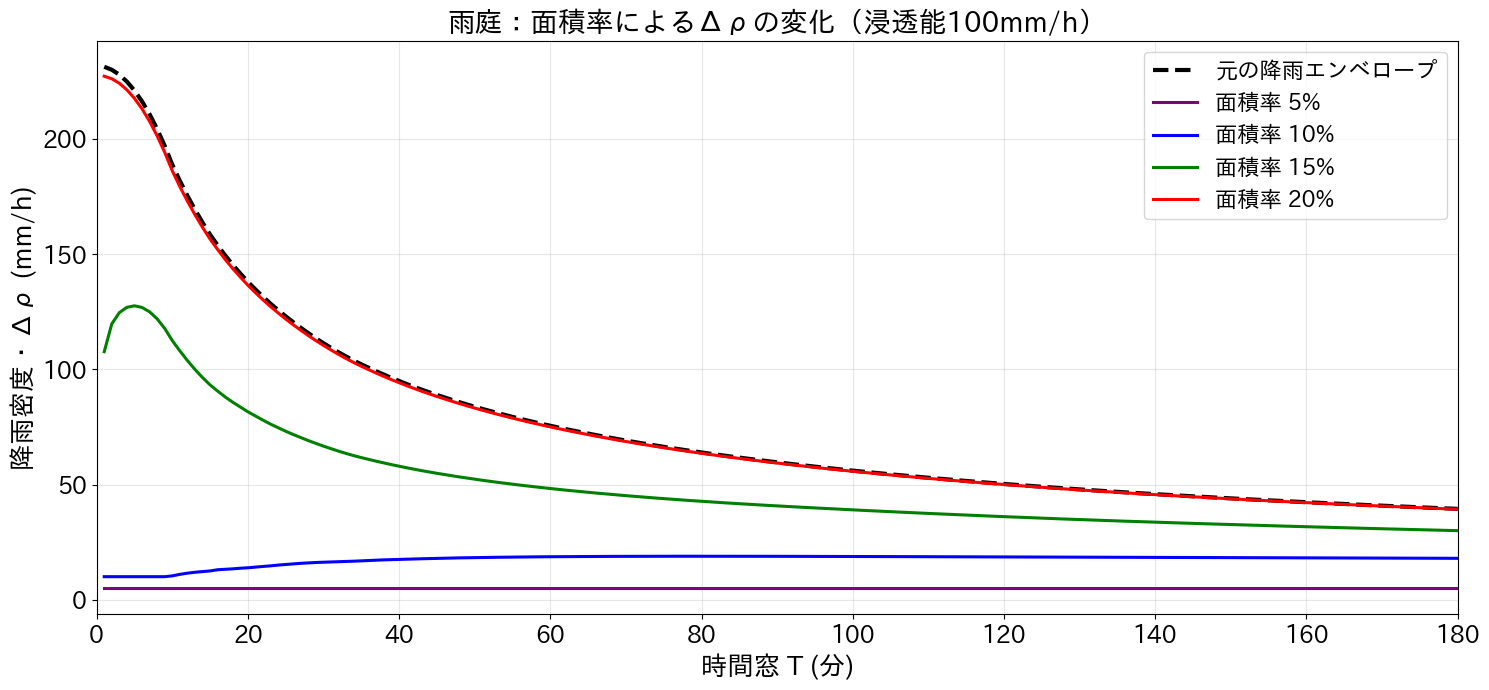

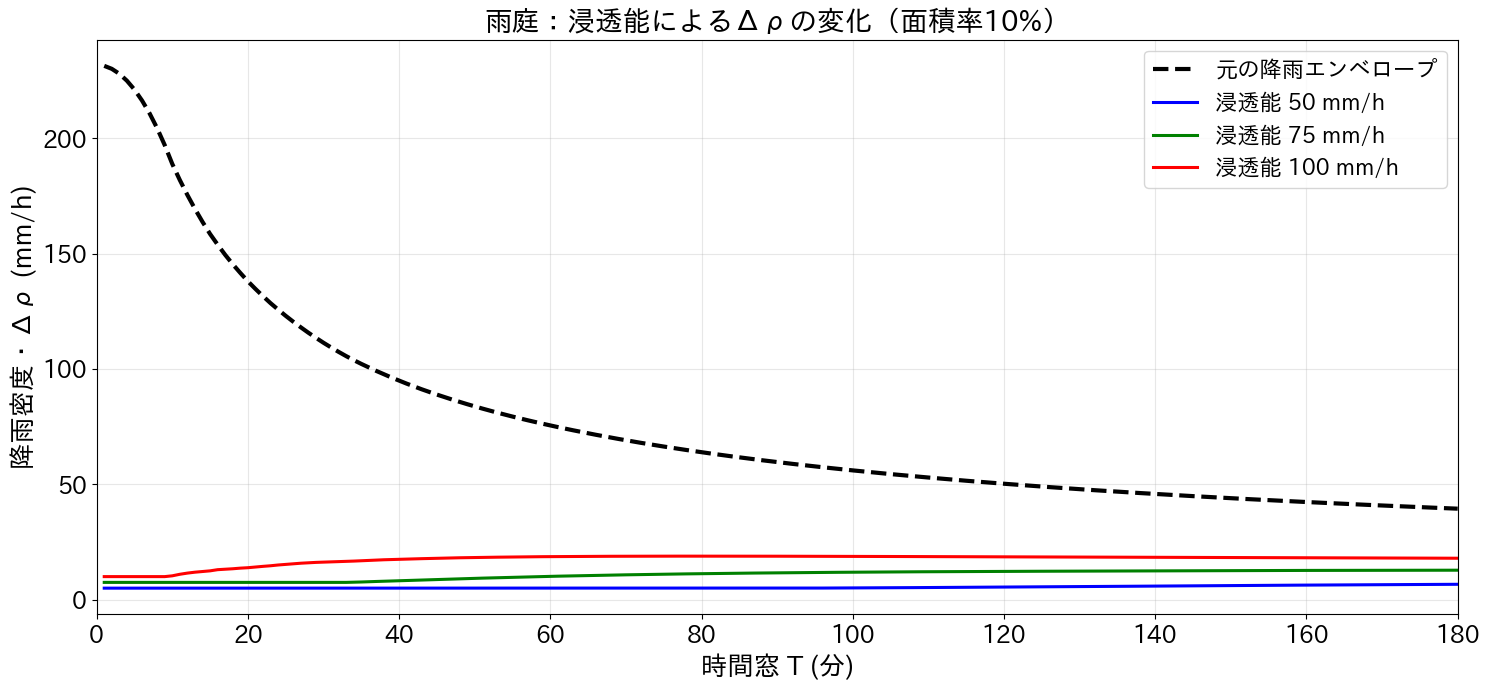

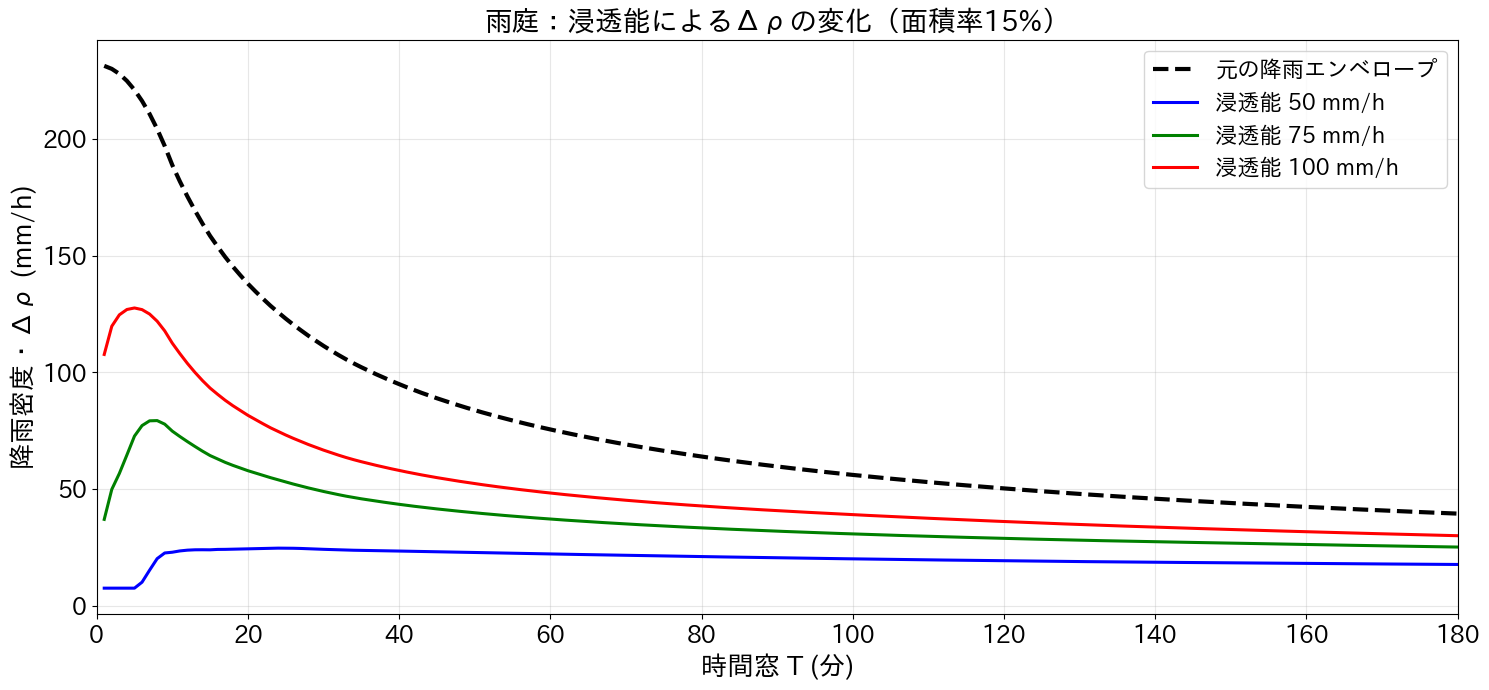

===== 雨庭：面積率・浸透能比較 =====


,面積率(%),浸透能(mm/h),貯留容量(mm),最大水深(cm),総流出高(mm),最大流出強度(mm/h),最大Δρ(mm/h)
0,5,50,15.0,30.0,176.790,228.821,2.500
1,5,75,15.0,30.0,146.830,227.571,3.750
2,5,100,15.0,30.0,123.664,226.321,5.000
3,10,50,30.0,30.0,108.664,226.321,6.672
4,10,75,30.0,30.0,81.282,223.821,12.780
5,10,100,30.0,30.0,64.409,221.321,18.873
6,15,50,45.0,30.0,66.282,223.821,24.647
7,15,75,45.0,30.0,42.976,194.348,79.305
8,15,100,45.0,30.0,28.381,123.669,127.567
9,20,50,60.0,30.0,34.409,94.215,140.875


In [ ]:
# ============================================================
# Step 6：雨庭面積率と浸透能の比較
# 面積率：5, 10, 15, 20 %
# 浸透能：50, 75, 100 mm/h
# 貯留深：30 cm
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. 計算条件
# ------------------------------------------------------------

AREA_RATIOS = [5, 10, 15, 20]   # 雨庭面積率 [%]
INFIL_RATES = [50, 75, 100]     # 浸透能 [mm/h]

CATCHMENT_AREA = 100.0         # 集水域全体 [m²]
RG_DEPTH = 0.30                 # 貯留深 [m]

rain = np.asarray(r_1min, dtype=float)
time = np.arange(len(rain))

if not np.all(np.isfinite(rain)) or np.any(rain < 0):
    raise ValueError("r_1min に不正な値があります")

colors = {
    5: "purple",
    10: "blue",
    15: "green",
    20: "red"
}

# ------------------------------------------------------------
# 2. 雨庭モデル
# ------------------------------------------------------------

def calc_rg_ratio(rain, area_ratio, infil_rate):

    rg_area = CATCHMENT_AREA * area_ratio / 100
    capacity = rg_area * RG_DEPTH

    infil_capacity = (
        infil_rate / 1000 / 60 * rg_area
    )

    storage = 0.0

    n = len(rain)
    runoff = np.zeros(n)
    depth = np.zeros(n + 1)
    infiltration = np.zeros(n)

    for i in range(n):

        # 集水域全体の降雨流入
        vin = rain[i] / 1000 * CATCHMENT_AREA
        storage += vin

        # 浸透
        vi = min(storage, infil_capacity)
        storage -= vi

        # 越流
        vover = max(storage - capacity, 0.0)
        storage -= vover

        # 集水域全体に換算した流出高
        runoff[i] = vover / CATCHMENT_AREA * 1000
        infiltration[i] = vi / CATCHMENT_AREA * 1000
        depth[i+1] = storage / rg_area

    return runoff, depth, infiltration


# ------------------------------------------------------------
# 3. エンベロープ計算
# ------------------------------------------------------------

def calc_envelope(wave, windows):

    cumulative = np.insert(
        np.cumsum(np.asarray(wave, dtype=float)),
        0, 0.0
    )

    return np.array([
        np.max((cumulative[T:] - cumulative[:-T]) / T)
        for T in windows
    ])


MAX_WINDOW = min(180, len(rain))
windows = np.arange(1, MAX_WINDOW + 1)

E_rain = calc_envelope(rain, windows) * 60

# ------------------------------------------------------------
# 4. 全ケース計算
# ------------------------------------------------------------

rg_results = {}
delta_results = {}
result_table = []

for ratio in AREA_RATIOS:
    for f in INFIL_RATES:

        runoff, depth, infiltration = calc_rg_ratio(
            rain, ratio, f
        )

        E_runoff = calc_envelope(runoff, windows) * 60
        delta = E_rain - E_runoff

        rg_results[(ratio, f)] = runoff
        delta_results[(ratio, f)] = delta

        result_table.append({
            "面積率(%)": ratio,
            "浸透能(mm/h)": f,
            "貯留容量(mm)": RG_DEPTH * 1000 * ratio / 100,
            "最大水深(cm)": np.max(depth) * 100,
            "総流出高(mm)": np.sum(runoff),
            "最大流出強度(mm/h)": np.max(runoff) * 60,
            "最大Δρ(mm/h)": np.max(delta)
        })

# ------------------------------------------------------------
# 5. グラフ①：ハイドログラフ
# 浸透能75mm/hで面積率を比較
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    time, rain * 60,
    "k--", linewidth=3,
    label="元の降雨"
)

for ratio in AREA_RATIOS:
    plt.plot(
        time,
        rg_results[(ratio, 75)] * 60,
        color=colors[ratio],
        linewidth=2.2,
        label=f"面積率 {ratio}%"
    )

plt.xlabel("時間 (分)", fontsize=19)
plt.ylabel("流出強度 (mm/h)", fontsize=19)
plt.title("雨庭：面積率による流出高の変化（浸透能75mm/h）",
          fontsize=20)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)
plt.legend(fontsize=16)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. グラフ②：Δρエンベロープ
# 浸透能別に面積率を比較（3枚）
# ------------------------------------------------------------

for f in INFIL_RATES:

    plt.figure(figsize=(15, 7))

    plt.plot(
        windows, E_rain,
        "k--", linewidth=3,
        label="元の降雨エンベロープ"
    )

    for ratio in AREA_RATIOS:

        plt.plot(
            windows,
            delta_results[(ratio, f)],
            color=colors[ratio],
            linewidth=2.2,
            label=f"面積率 {ratio}%"
        )

    plt.xlabel("時間窓 T (分)", fontsize=19)
    plt.ylabel("降雨密度・Δρ (mm/h)", fontsize=19)
    plt.title(
        f"雨庭：面積率によるΔρの変化（浸透能{f}mm/h）",
        fontsize=20
    )

    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)
    plt.legend(fontsize=16)
    plt.grid(alpha=0.3)
    plt.xlim(0, MAX_WINDOW)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. グラフ③：浸透能比較
# 面積率10%、15%を比較
# ------------------------------------------------------------

infil_colors = {
    50: "blue",
    75: "green",
    100: "red"
}

for ratio in [10, 15]:

    plt.figure(figsize=(15, 7))

    plt.plot(
        windows, E_rain,
        "k--", linewidth=3,
        label="元の降雨エンベロープ"
    )

    for f in INFIL_RATES:

        plt.plot(
            windows,
            delta_results[(ratio, f)],
            color=infil_colors[f],
            linewidth=2.2,
            label=f"浸透能 {f} mm/h"
        )

    plt.xlabel("時間窓 T (分)", fontsize=19)
    plt.ylabel("降雨密度・Δρ (mm/h)", fontsize=19)
    plt.title(
        f"雨庭：浸透能によるΔρの変化（面積率{ratio}%）",
        fontsize=20
    )
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)
    plt.legend(fontsize=16)
    plt.grid(alpha=0.3)
    plt.xlim(0, MAX_WINDOW)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. 結果表
# ------------------------------------------------------------

result_df = pd.DataFrame(result_table)

print("===== 雨庭：面積率・浸透能比較 =====")
display(result_df.round(3))

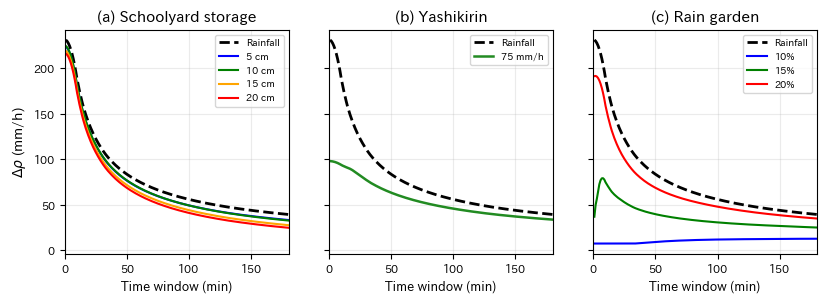

In [ ]:
# ============================================================
# A4縦・横3列・各グラフ正方形
# (a) 校庭貯留 (b) 屋敷林 (c) 雨庭
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

school_diams = [5, 10, 15, 20]
rg_ratios = [10, 15, 20]

school_colors = {
    5: "blue", 10: "green",
    15: "orange", 20: "red"
}
rg_colors = {
    10: "blue", 15: "green", 20: "red"
}

# A4縦・横3列
fig, axes = plt.subplots(
    1, 3,
    figsize=(8.27, 11.69),
    sharex=True,
    sharey=True
)

# (a) 校庭貯留
ax = axes[0]
ax.plot(windows, E_rain, "k--", lw=2, label="Rainfall")

for d in school_diams:
    ax.plot(
        windows, delta_rho[d],
        color=school_colors[d], lw=1.5,
        label=f"{d} cm"
    )

ax.set_title("(a) Schoolyard storage", fontsize=11)
ax.set_ylabel(r"$\Delta\rho$ (mm/h)", fontsize=10)
ax.legend(fontsize=7, loc="upper right")

# (b) 屋敷林
ax = axes[1]
ax.plot(windows, E_rain, "k--", lw=2, label="Rainfall")
ax.plot(
    windows, delta_rho_forest[75],
    color="forestgreen", lw=1.8,
    label="75 mm/h"
)

ax.set_title("(b) Yashikirin", fontsize=11)
ax.legend(fontsize=7, loc="upper right")

# (c) 雨庭
ax = axes[2]
ax.plot(windows, E_rain, "k--", lw=2, label="Rainfall")

for ratio in rg_ratios:
    ax.plot(
        windows, delta_results[(ratio, 75)],
        color=rg_colors[ratio], lw=1.5,
        label=f"{ratio}%"
    )

ax.set_title("(c) Rain garden", fontsize=11)
ax.legend(fontsize=7, loc="upper right")

# 共通設定
for ax in axes:
    ax.set_box_aspect(1)  # 描画領域を正方形にする
    ax.set_xlim(0, 180)
    ax.set_xlabel("Time window (min)", fontsize=9)
    ax.tick_params(axis="both", labelsize=8)
    ax.grid(True, alpha=0.25)

# 横並びの余白調整
fig.subplots_adjust(
    left=0.08,
    right=0.99,
    wspace=0.18
)

plt.show()

# 保存
fig.savefig(
    "three_facilities_square_A4.png",
    dpi=300
)
fig.savefig(
    "three_facilities_square_A4.pdf"
)

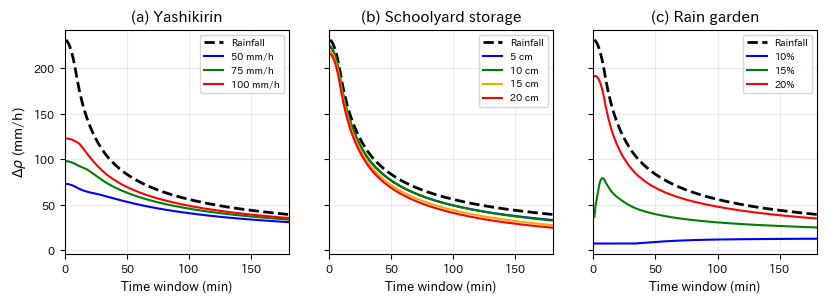

In [ ]:
# ============================================================
# A4縦・横3列・各グラフ正方形
# (a) 屋敷林 (b) 校庭貯留 (c) 雨庭
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

school_diams = [5, 10, 15, 20]
forest_infil = [50, 75, 100]
rg_ratios = [10, 15, 20]

school_colors = {
    5: "blue", 10: "green",
    15: "orange", 20: "red"
}
forest_colors = {
    50: "blue", 75: "green", 100: "red"
}
rg_colors = {
    10: "blue", 15: "green", 20: "red"
}

# A4縦・横3列
fig, axes = plt.subplots(
    1, 3,
    figsize=(8.27, 11.69),
    sharex=True,
    sharey=True
)

# ------------------------------------------------------------
# (a) 屋敷林
# ------------------------------------------------------------
ax = axes[0]
ax.plot(windows, E_rain, "k--", lw=2, label="Rainfall")

for infil in forest_infil:
    ax.plot(
        windows, delta_rho_forest[infil],
        color=forest_colors[infil], lw=1.5,
        label=f"{infil} mm/h"
    )

ax.set_title("(a) Yashikirin", fontsize=11)
ax.set_ylabel(r"$\Delta\rho$ (mm/h)", fontsize=10)
ax.legend(fontsize=7, loc="upper right")

# ------------------------------------------------------------
# (b) 校庭貯留
# ------------------------------------------------------------
ax = axes[1]
ax.plot(windows, E_rain, "k--", lw=2, label="Rainfall")

for d in school_diams:
    ax.plot(
        windows, delta_rho[d],
        color=school_colors[d], lw=1.5,
        label=f"{d} cm"
    )

ax.set_title("(b) Schoolyard storage", fontsize=11)
ax.legend(fontsize=7, loc="upper right")

# ------------------------------------------------------------
# (c) 雨庭
# ------------------------------------------------------------
ax = axes[2]
ax.plot(windows, E_rain, "k--", lw=2, label="Rainfall")

for ratio in rg_ratios:
    ax.plot(
        windows, delta_results[(ratio, 75)],
        color=rg_colors[ratio], lw=1.5,
        label=f"{ratio}%"
    )

ax.set_title("(c) Rain garden", fontsize=11)
ax.legend(fontsize=7, loc="upper right")

# 共通設定
for ax in axes:
    ax.set_box_aspect(1)
    ax.set_xlim(0, 180)
    ax.set_xlabel("Time window (min)", fontsize=9)
    ax.tick_params(axis="both", labelsize=8)
    ax.grid(True, alpha=0.25)

fig.subplots_adjust(
    left=0.08,
    right=0.99,
    wspace=0.18
)

plt.show()

fig.savefig("three_facilities_square_A4.png", dpi=300)
fig.savefig("three_facilities_square_A4.pdf")

In [ ]:
# ============================================================
# 時間の窓60分における Δρ の一覧表示
# (a) 屋敷林 (b) 校庭貯留 (c) 雨庭
# ============================================================

import numpy as np

T_target = 60.0

# windows に60分がなくても線形補間で求める
def value_at_60(values):
    return np.interp(T_target, windows, values)

print("=" * 55)
print("Time window = 60 min")
print("Δρ (mm/h)")
print("=" * 55)

# 降雨
print(f"Rainfall                : {value_at_60(E_rain):8.3f}")

# (a) 屋敷林
print("\n(a) Yashikirin")
for infil in [50, 75, 100]:
    value = value_at_60(delta_rho_forest[infil])
    print(f"  {infil:3d} mm/h            : {value:8.3f}")

# (b) 校庭貯留
print("\n(b) Schoolyard storage")
for d in [5, 10, 15, 20]:
    value = value_at_60(delta_rho[d])
    print(f"  {d:3d} cm              : {value:8.3f}")

# (c) 雨庭
print("\n(c) Rain garden")
for ratio in [10, 15, 20]:
    value = value_at_60(delta_results[(ratio, 75)])
    print(f"  {ratio:3d} %               : {value:8.3f}")

print("=" * 55)

Time window = 60 min
Δρ (mm/h)
Rainfall                :   75.502

(a) Yashikirin
   50 mm/h            :   50.193
   75 mm/h            :   58.582
  100 mm/h            :   63.833

(b) Schoolyard storage
    5 cm              :   68.578
   10 cm              :   68.824
   15 cm              :   63.631
   20 cm              :   60.532

(c) Rain garden
   10 %               :   10.114
   15 %               :   37.116
   20 %               :   62.501
